# Question Answering: the questions a model must refuse to answer

**The question:** the legacy notebook trained a BERT question-answering model (through the `simpletransformers` library, which is no longer maintained) on **seven hand-written questions** about the Mistborn novels, and showed it answering one more. Seven questions cannot say whether a model is good. *How well do today's pretrained models do on a proper benchmark, SQuAD 2.0, where **half of the questions have no answer in the paragraph**? What happens to a model that was never taught to say "I don't know"? Can its refusal threshold be tuned? Which kinds of question are hard? And how would these models have done on the legacy notebook's own seven questions?*

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit: the questions
4. Hypotheses and why we chose each test
5. The models
6. H1: does saying "no answer" matter?
7. H2: can the refusal threshold be tuned?
8. H3: which questions are hard?
9. H4: the legacy questions, replayed
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab NLP/question-answering/question_answering.ipynb`, or *Run All* in any Jupyter. SQuAD 2.0 (a few MB) and the two models (about 650 MB in total) download themselves on the first run. It uses a GPU if present and takes about 15 minutes on one.

## 1. 💡 The simple analogy

Imagine an **open-book exam** where you get a paragraph and a question and must **underline the answer**.

- A student who has only ever seen questions that *have* an answer will **always underline something**, even when the paragraph is silent: ask "Who is the main character?" about a paragraph that never says, and he underlines "The Hero of Ages", because it is a name.
- A student who has also practised **questions with no answer** learns to write "not in the text". On an exam where half of the questions are traps, this is the whole difference between a failing and a passing mark.
- The risk is that the second student becomes **too cautious** and writes "not in the text" for answers that were there. His **caution threshold** can be adjusted.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the window size (384 word-pieces, with an overlap of 128) and the longest answer allowed (30 word-pieces) keeps the notebook reproducible and avoids "magic numbers". Long paragraphs are split into overlapping windows and the best answer over all windows is kept.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
import json
import re
import string
from collections import Counter
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from huggingface_hub.utils import logging as hub_logging
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from transformers import AutoModelForQuestionAnswering, AutoTokenizer
from transformers.utils import logging as hf_logging

hub_logging.set_verbosity_error()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
datasets.disable_progress_bars()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
MODEL_V1 = "distilbert-base-cased-distilled-squad"  # trained only on questions that have answers
MODEL_V2 = "deepset/roberta-base-squad2"  # trained on answerable and unanswerable questions
SEED = 365
MAX_LEN = 384
STRIDE = 128
MAX_ANSWER_TOKENS = 30
BATCH = 32
N_BOOTSTRAP = 1_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Audit: the questions

*What:* the **SQuAD 2.0 development set**: questions written by crowd workers about Wikipedia paragraphs. Each answerable question has several reference answers (written by different people). Each unanswerable question looks like an answerable one but its answer is **not in the paragraph**. We look at how many of each there are, the paragraph length and the kinds of question (by their first question word). *Why:* a model that always answers can score at most about 50% here, so the balance is part of the result.

> **Problems in the legacy notebook this replaces:** it trained on **seven** invented questions (four for training, three for testing), so any score would be noise; it used the unmaintained `simpletransformers` wrapper and downloaded its model on the fly; it ran Windows shell commands (`rm -rf outputs`) inside the notebook; and it never reported a metric.

In [2]:
dev = load_dataset("rajpurkar/squad_v2", split="validation", cache_dir=str(DATA_DIR / "hf"))
dev = dev.to_pandas()
dev["gold"] = dev["answers"].map(lambda a: list(a["text"]))
dev["answerable"] = dev["gold"].map(len) > 0
dev["context_words"] = dev["context"].str.split().str.len()
dev["wh"] = (
    dev["question"]
    .str.lower()
    .str.extract(r"\b(what|who|whom|whose|when|where|why|how|which)\b", expand=False)
    .fillna("other")
)
dev["wh"] = dev["wh"].replace({"whom": "who", "whose": "who"})
print(
    f"{len(dev):,} questions about {dev['title'].nunique()} Wikipedia articles "
    f"({dev['context'].nunique():,} paragraphs)"
)
print(
    f"Answerable: {dev['answerable'].sum():,} ({dev['answerable'].mean():.1%}); "
    f"unanswerable: {(~dev['answerable']).sum():,}"
)
print(
    "Context length in words: median {:.0f}, 90th percentile {:.0f}, longest {}".format(
        dev["context_words"].median(),
        dev["context_words"].quantile(0.9),
        dev["context_words"].max(),
    )
)
print(
    "Questions by first question word: "
    + ", ".join(f"{k} {v / len(dev):.0%}" for k, v in dev["wh"].value_counts().items())
)
gold_counts = dev.loc[dev["answerable"], "gold"].map(len)
print(
    f"Reference answers per answerable question: median {gold_counts.median():.0f} "
    f"(spread of the references is what exact match forgives)"
)

11,873 questions about 35 Wikipedia articles (1,204 paragraphs)
Answerable: 5,928 (49.9%); unanswerable: 5,945
Context length in words: median 114, 90th percentile 191, longest 629
Questions by first question word: what 63%, how 11%, who 9%, when 6%, which 4%, where 4%, why 2%, other 1%
Reference answers per answerable question: median 3 (spread of the references is what exact match forgives)


**How to read this:**

- **11,873 questions** about 35 Wikipedia articles (1,204 paragraphs): **5,928 answerable (49.9%)** and **5,945 not (50.1%)**. The two kinds are about equally common, so "always answer" is capped at about 50%.
- **Paragraphs are short:** median **114** words, 90th percentile 191, longest 629.
- **Most questions start with "what"** (63%); how 11%, who 9%, when 6%, which 4%, where 4% and why only 2%.
- **A forgiving reference:** the median answerable question has **3** reference answers, so a prediction only needs to match one of them. This is what "exact match" forgives.

## 4. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Does a model that is allowed to say "no answer" do better on SQuAD 2.0 than one that must always answer? | Same score | Better | Exact match and F1 with bootstrap CIs; exact McNemar test on answerable and unanswerable questions separately |
| H2 | Does tuning the "no answer" threshold improve the score? | Same as the default | Better | Threshold chosen on one half of the questions, judged on the other; bootstrap CI |
| H3 | Is the model equally good on every kind of question and every paragraph length? | Same F1 | Differs | Kruskal-Wallis across question words; Spearman correlation with paragraph length |
| H4 | How would the two models do on the legacy notebook's seven questions? | (descriptive) | | Exact match and F1 on seven questions |

*Why these tests?* Both kinds of system are scored on the **same questions**, so the exact **McNemar test**, which uses only the questions where two systems disagree, is the fair comparison. F1 is skewed (many 0s and 1s), so the Kruskal-Wallis test, which uses ranks, is the safe test across question types. Splitting the questions in two for H2 stops us from choosing the threshold on the questions that judge it.

## 5. The models

*What:* two extractive question-answering models (they pick a span of the paragraph as the answer).

- **DistilBERT, trained on SQuAD 1.1 only** (`distilbert-base-cased-distilled-squad`): it has only ever seen questions that have an answer, so it always picks a span.
- **RoBERTa-base, trained on SQuAD 2.0** (`deepset/roberta-base-squad2`): it has also seen unanswerable questions. Besides the best span, it gives a score for "no answer". We use the **margin** (its "no answer" score minus its best span's score): above 0, it prefers "no answer".

We run three *systems*: DistilBERT (always answers), RoBERTa **forced to answer** (the same model, ignoring its "no answer" score), and RoBERTa **allowed to say "no answer"** (margin above 0). The comparison between the two RoBERTa systems isolates the effect of abstaining; DistilBERT is a different, smaller model, so it is **not** a clean comparison with RoBERTa. Answers are scored with the official SQuAD **exact match** (the same text after normalising case, punctuation and articles) and **F1** (word overlap), best over the reference answers; for unanswerable questions the correct answer is the empty string.

In [3]:
def normalise(text: str) -> str:
    """The official SQuAD answer normalisation: lower-case, no punctuation, no articles."""
    text = "".join(ch for ch in text.lower() if ch not in set(string.punctuation))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())


def exact_match(pred: str, golds: list[str]) -> float:
    """1 if the prediction equals any reference answer after normalisation, else 0."""
    return float(any(normalise(pred) == normalise(g) for g in (golds or [""])))


def f1_score(pred: str, golds: list[str]) -> float:
    """Best word-overlap F1 between the prediction and any reference answer."""
    best = 0.0
    for gold in golds or [""]:
        p, g = normalise(pred).split(), normalise(gold).split()
        if not p or not g:
            best = max(best, float(p == g))
            continue
        common = sum((Counter(p) & Counter(g)).values())
        if common:
            precision, recall = common / len(p), common / len(g)
            best = max(best, 2 * precision * recall / (precision + recall))
    return best


def predict_spans(
    model_name: str, questions: list[str], contexts: list[str]
) -> tuple[list[str], np.ndarray]:
    """Finds the best answer span for each question, and how much the model prefers 'no answer'.

    Long paragraphs are split into overlapping windows; the best span over all windows is kept.

    Args:
        model_name: A Hugging Face extractive question-answering model.
        questions: The questions.
        contexts: The paragraph for each question.

    Returns:
        The best span of text for each question (never empty) and a "no-answer margin": the
        model's score for 'no answer' minus its best span's score (above 0 means it leans towards
        'no answer'). Models trained without unanswerable questions have a meaningless margin.
    """
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForQuestionAnswering.from_pretrained(model_name).to(DEVICE).eval()
    enc = tok(
        questions,
        contexts,
        truncation="only_second",
        max_length=MAX_LEN,
        stride=STRIDE,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding="max_length",
    )
    n_features = len(enc["input_ids"])
    starts, ends = [], []
    with torch.no_grad():
        for i in range(0, n_features, BATCH):
            out = model(
                input_ids=torch.tensor(enc["input_ids"][i : i + BATCH], device=DEVICE),
                attention_mask=torch.tensor(enc["attention_mask"][i : i + BATCH], device=DEVICE),
            )
            starts.append(out.start_logits.float().cpu().numpy())
            ends.append(out.end_logits.float().cpu().numpy())
    starts, ends = np.concatenate(starts), np.concatenate(ends)
    best_score = np.full(len(questions), -np.inf)
    null_score = np.full(len(questions), np.inf)
    best_text = [""] * len(questions)
    for f in range(n_features):
        q = enc["overflow_to_sample_mapping"][f]
        in_context = np.array([s == 1 for s in enc.sequence_ids(f)])
        offsets = enc["offset_mapping"][f]
        null_score[q] = min(null_score[q], starts[f][0] + ends[f][0])
        for a in np.argsort(starts[f])[-20:]:
            for b in np.argsort(ends[f])[-20:]:
                if in_context[a] and in_context[b] and a <= b < a + MAX_ANSWER_TOKENS:
                    score = starts[f][a] + ends[f][b]
                    if score > best_score[q]:
                        best_score[q] = score
                        best_text[q] = contexts[q][offsets[a][0] : offsets[b][1]]
    del model
    torch.cuda.empty_cache()
    return best_text, null_score - best_score


questions, contexts = dev["question"].tolist(), dev["context"].tolist()
v1_text, _ = predict_spans(MODEL_V1, questions, contexts)
v2_text, v2_margin = predict_spans(MODEL_V2, questions, contexts)
dev["v1_text"], dev["v2_text"], dev["v2_margin"] = v1_text, v2_text, v2_margin
print(f"Scored {len(dev):,} questions with two models.")

Scored 11,873 questions with two models.


**How to read this:** both models score all **11,873** questions. The slow part is the models themselves; the scoring is the same as the official SQuAD script.

## 6. H1: does saying "no answer" matter?

*What:* exact match and F1 for the three systems on three groups: answerable questions, unanswerable questions and all questions, with 95% bootstrap intervals for F1. Then an exact McNemar test comparing the two RoBERTa systems separately on answerable and on unanswerable questions. *Why:* a headline score on a benchmark that is half traps depends mostly on what happens to the traps.

In [4]:
def systems(threshold: float | None = 0.0) -> dict[str, list[str]]:
    """The answers of the three systems; the 'no answer' decision uses ``threshold``."""
    abstain = dev["v2_margin"].to_numpy() > (np.inf if threshold is None else threshold)
    return {
        "DistilBERT (SQuAD 1 only)": dev["v1_text"].tolist(),
        "RoBERTa, forced to answer": dev["v2_text"].tolist(),
        "RoBERTa, may say 'no answer'": [
            "" if a else t for a, t in zip(abstain, dev["v2_text"], strict=True)
        ],
    }


def scores(answers: list[str]) -> pd.DataFrame:
    """Exact match and F1 of each answer against its references."""
    pairs = list(zip(answers, dev["gold"], strict=True))
    return pd.DataFrame(
        {"em": [exact_match(p, g) for p, g in pairs], "f1": [f1_score(p, g) for p, g in pairs]}
    )


def bootstrap_mean(values: np.ndarray) -> tuple[float, float, float]:
    """Mean with a 95% bootstrap interval resampling questions."""
    boots = [values[rng.integers(0, len(values), len(values))].mean() for _ in range(N_BOOTSTRAP)]
    return float(values.mean()), *np.percentile(boots, [2.5, 97.5])


results = {name: scores(ans) for name, ans in systems(0.0).items()}
has, no = dev["answerable"].to_numpy(), ~dev["answerable"].to_numpy()
rows = []
for name, sc in results.items():
    for part, mask in [("answerable", has), ("unanswerable", no), ("all", np.ones(len(dev), bool))]:
        f1, lo, hi = bootstrap_mean(sc["f1"].to_numpy()[mask])
        rows.append(
            {
                "system": name,
                "questions": part,
                "EM": sc["em"].to_numpy()[mask].mean(),
                "F1": f1,
                "F1 low": lo,
                "F1 high": hi,
            }
        )
table = pd.DataFrame(rows)
print(table.pivot(index="system", columns="questions", values=["EM", "F1"]).round(3).to_string())
forced, flexible = results["RoBERTa, forced to answer"], results["RoBERTa, may say 'no answer'"]
for part, mask in [("answerable", has), ("unanswerable", no)]:
    a, b = forced["em"].to_numpy()[mask] == 1, flexible["em"].to_numpy()[mask] == 1
    mc = mcnemar(
        [[int((a & b).sum()), int((a & ~b).sum())], [int((~a & b).sum()), int((~a & ~b).sum())]],
        exact=True,
    )
    print(
        f"Allowed to say 'no answer' vs forced, {part}: right only when forced "
        f"{int((a & ~b).sum())}, right only when allowed {int((~a & b).sum())}; "
        f"exact McNemar p = {fmt_p(mc.pvalue)}"
    )

                                 EM                             F1                        
questions                       all answerable unanswerable    all answerable unanswerable
system                                                                                    
DistilBERT (SQuAD 1 only)     0.397      0.794        0.000  0.435      0.871        0.000
RoBERTa, forced to answer     0.421      0.843        0.000  0.456      0.914        0.000
RoBERTa, may say 'no answer'  0.799      0.780        0.818  0.829      0.840        0.818
Allowed to say 'no answer' vs forced, answerable: right only when forced 371, right only when allowed 0; exact McNemar p = 4.2e-112
Allowed to say 'no answer' vs forced, unanswerable: right only when forced 0, right only when allowed 4864; exact McNemar p = < 1e-300


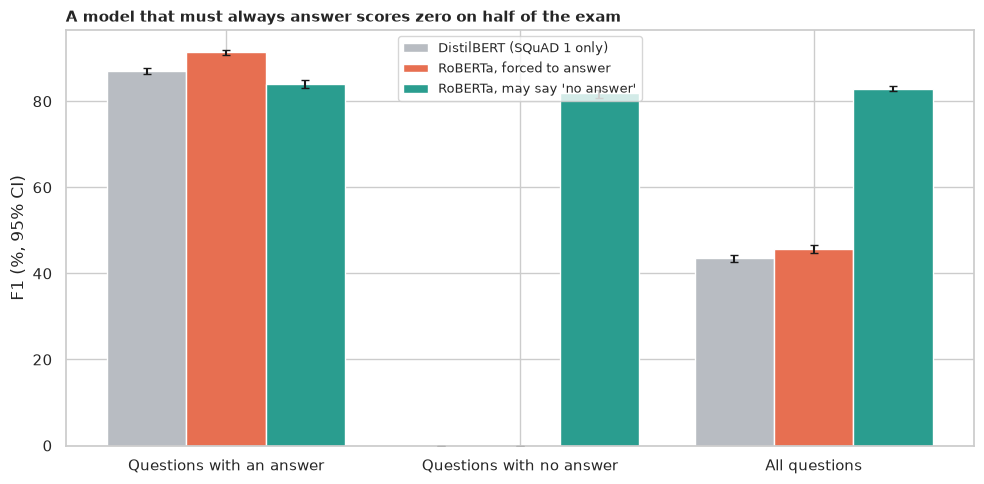

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
for shift, (name, color) in zip(
    [-0.27, 0, 0.27],
    [
        ("DistilBERT (SQuAD 1 only)", GREY),
        ("RoBERTa, forced to answer", ORANGE),
        ("RoBERTa, may say 'no answer'", TEAL),
    ],
    strict=True,
):
    sub = (
        table[table["system"] == name]
        .set_index("questions")
        .loc[["answerable", "unanswerable", "all"]]
    )
    ax.bar(
        x + shift,
        sub["F1"] * 100,
        0.27,
        color=color,
        label=name,
        yerr=[(sub["F1"] - sub["F1 low"]) * 100, (sub["F1 high"] - sub["F1"]) * 100],
        capsize=3,
    )
ax.set_xticks(x, ["Questions with an answer", "Questions with no answer", "All questions"])
ax.set_ylabel("F1 (%, 95% CI)")
ax.set_title(
    "A model that must always answer scores zero on half of the exam",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
ax.legend(loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_answerable_vs_not.png", dpi=150)
plt.show()

**How to read this:**

- **A model that must answer scores zero on half of the exam.** DistilBERT and the forced RoBERTa both score **0.000** exact match on the unanswerable questions, by construction, so their overall exact match is only **0.397** and **0.421**, however good their span-finding is: on the answerable questions they reach **0.794** and **0.843** exact match (F1 **0.871** and **0.914**).
- **Allowing "no answer" transforms the result:** the RoBERTa that may abstain scores **0.818** exact match on unanswerable questions and **0.799** overall (F1 **0.829**), against **0.421** when forced.
- **It has a price:** on answerable questions its exact match falls from **0.843** to **0.780** (F1 0.914 to 0.840): the exact McNemar test finds **371** answerable questions right only when forced and **0** right only when allowed (p = 4e-112). On unanswerable questions, **4,864** are right only when allowed and **0** only when forced (p below 1e-300). **We reject H₀:** the net gain is about 38 points of exact match.
- DistilBERT is a smaller model and is not the same comparison, but its answerable-question score (0.794 exact match) is 5 points below RoBERTa's, as you would expect from a smaller network.

## 7. H2: can the refusal threshold be tuned?

*What:* the "no answer" decision is a threshold on the margin: above it, the model refuses. The default is 0. We split the questions in two halves at random, find the threshold with the best F1 on the first half (trying 81 values from -10 to 10), and judge it on the second half, with a bootstrap interval. The figure shows the F1 curve on both halves. *Why:* a threshold chosen on the same questions it is judged on is optimistic; and the threshold is the model's one knob for trading refusals against wrong answers.

In [6]:
order = rng.permutation(len(dev))
tune, hold = np.sort(order[: len(dev) // 2]), np.sort(order[len(dev) // 2 :])
grid = np.linspace(-10, 10, 81)


def f1_at(threshold: float, rows: np.ndarray) -> float:
    """Overall F1 on the given questions when 'no answer' is chosen above ``threshold``."""
    abstain = dev["v2_margin"].to_numpy()[rows] > threshold
    f1 = [
        f1_score("" if a else dev["v2_text"].iloc[i], dev["gold"].iloc[i])
        for a, i in zip(abstain, rows, strict=True)
    ]
    return float(np.mean(f1))


curve = pd.DataFrame(
    {
        "threshold": grid,
        "tune": [f1_at(t, tune) for t in grid],
        "hold": [f1_at(t, hold) for t in grid],
    }
)
best = float(curve.loc[curve["tune"].idxmax(), "threshold"])
print(
    f"Threshold chosen on the first half ({len(tune):,} questions): {best:+.2f} (the default is 0)"
)
for label, thr in [("default (0)", 0.0), (f"tuned ({best:+.2f})", best)]:
    f = f1_at(thr, hold)
    boots = []
    abstain = dev["v2_margin"].to_numpy()[hold] > thr
    per = np.array(
        [
            f1_score("" if a else dev["v2_text"].iloc[i], dev["gold"].iloc[i])
            for a, i in zip(abstain, hold, strict=True)
        ]
    )
    lo, hi = np.percentile(
        [per[rng.integers(0, len(per), len(per))].mean() for _ in range(N_BOOTSTRAP)], [2.5, 97.5]
    )
    print(f"  second half, threshold {label}: F1 {f:.4f} (95% CI {lo:.4f} to {hi:.4f})")
abstain_default = dev["v2_margin"].to_numpy()[hold] > 0
abstain_tuned = dev["v2_margin"].to_numpy()[hold] > best
print(
    f"  share of questions answered 'no answer': default {abstain_default.mean():.1%}, "
    f"tuned {abstain_tuned.mean():.1%} (true share {1 - dev['answerable'].iloc[hold].mean():.1%})"
)

Threshold chosen on the first half (5,936 questions): -1.50 (the default is 0)


  second half, threshold default (0): F1 0.8252 (95% CI 0.8159 to 0.8345)


  second half, threshold tuned (-1.50): F1 0.8296 (95% CI 0.8204 to 0.8392)
  share of questions answered 'no answer': default 45.7%, tuned 49.3% (true share 50.1%)


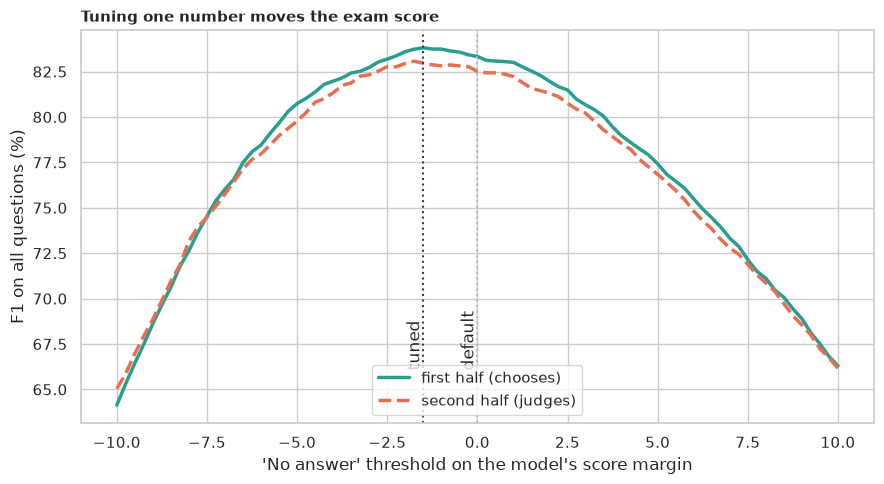

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["threshold"], curve["tune"] * 100, color=TEAL, lw=2.5, label="first half (chooses)")
ax.plot(
    curve["threshold"],
    curve["hold"] * 100,
    color=ORANGE,
    lw=2.5,
    ls="--",
    label="second half (judges)",
)
ax.axvline(0, color=GREY, ls=":", lw=1.5)
ax.axvline(best, color=NAVY, ls=":", lw=1.5)
ax.annotate("default", (0, curve["hold"].min() * 100 + 1), rotation=90, va="bottom", ha="right")
ax.annotate("tuned", (best, curve["hold"].min() * 100 + 1), rotation=90, va="bottom", ha="right")
ax.set_xlabel("'No answer' threshold on the model's score margin")
ax.set_ylabel("F1 on all questions (%)")
ax.set_title("Tuning one number moves the exam score", loc="left", fontweight="bold", fontsize=11)
ax.legend(loc="lower center")
fig.tight_layout()
fig.savefig(OUT_DIR / "02_threshold.png", dpi=150)
plt.show()

**How to read this:**

- **Tuning moves the threshold from 0 to -1.50:** the model should refuse a little more readily than its default. On the first half the best F1 is at -1.50.
- **The gain is small:** on the untouched second half, F1 is **0.8252** (95% CI 0.8159 to 0.8345) at the default and **0.8296** (0.8204 to 0.8392) with the tuned threshold: **+0.44 points**, with heavily overlapping intervals. We **cannot call it a clear win**; the curve is flat near the top.
- **The model is well calibrated about how often to refuse:** at the default it answers "no answer" for **45.7%** of the questions and with the tuned threshold for **49.3%**, against a true share of **50.1%**. Tuning mostly corrects a slight over-confidence in answering.
- **The lesson:** the default threshold of this model is already close to the best, so the large gains come from training with unanswerable questions (H1), not from tuning the threshold. We do **not** reject H₀ in a meaningful sense.

## 8. H3: which questions are hard?

*What:* on the answerable questions, the F1 of the abstaining RoBERTa for each question word (what, who, when, where, why, how, which; groups with at least 100 questions), with bootstrap intervals and a Kruskal-Wallis test; the Spearman correlation between paragraph length and F1; and what happens in the answerable questions it gets completely wrong. *Why:* we want to know *why* a model fails, not only how often.

In [8]:
dev["f1"] = flexible["f1"].to_numpy()
dev["em"] = flexible["em"].to_numpy()
answerable = dev[dev["answerable"]]
rows = []
for kind, group in answerable.groupby("wh"):
    if len(group) >= 100:
        m, lo, hi = bootstrap_mean(group["f1"].to_numpy())
        rows.append(
            {"question word": kind, "questions": len(group), "F1": m, "low": lo, "high": hi}
        )
by_word = pd.DataFrame(rows).sort_values("F1").set_index("question word")
print(by_word.round(3).to_string())
groups = [g["f1"].to_numpy() for k, g in answerable.groupby("wh") if len(g) >= 100]
kw = stats.kruskal(*groups)
print(
    f"\nKruskal-Wallis on F1 across question words: H = {kw.statistic:.1f}, p = {fmt_p(kw.pvalue)}"
)
rho = stats.spearmanr(answerable["context_words"], answerable["f1"])
print(
    f"Spearman correlation between paragraph length and F1: {rho.statistic:+.3f}, "
    f"p = {fmt_p(rho.pvalue)}"
)
answerable = answerable.assign(
    len_band=pd.qcut(
        answerable["context_words"], 4, labels=["shortest", "short", "long", "longest"]
    )
)
print(
    "F1 by paragraph length quarter: "
    + ", ".join(
        f"{k} {v:.3f}"
        for k, v in answerable.groupby("len_band", observed=True)["f1"].mean().items()
    )
)
wrong_answerable = answerable[(answerable["f1"] == 0)]
print(
    f"Answerable questions answered with F1 = 0: {len(wrong_answerable) / len(answerable):.1%}; "
    f"of these, the model said 'no answer' on {(wrong_answerable['v2_margin'] > 0).mean():.1%}"
)

               questions     F1    low   high
question word                                
why                  100  0.691  0.616  0.771
what                3618  0.835  0.824  0.847
where                255  0.850  0.809  0.888
who                  517  0.854  0.825  0.881
how                  647  0.857  0.833  0.881
when                 396  0.868  0.831  0.898
which                330  0.887  0.855  0.916

Kruskal-Wallis on F1 across question words: H = 69.5, p = 5.2e-13
Spearman correlation between paragraph length and F1: -0.004, p = 7.8e-01
F1 by paragraph length quarter: shortest 0.844, short 0.829, long 0.856, longest 0.832
Answerable questions answered with F1 = 0: 12.6%; of these, the model said 'no answer' on 76.6%


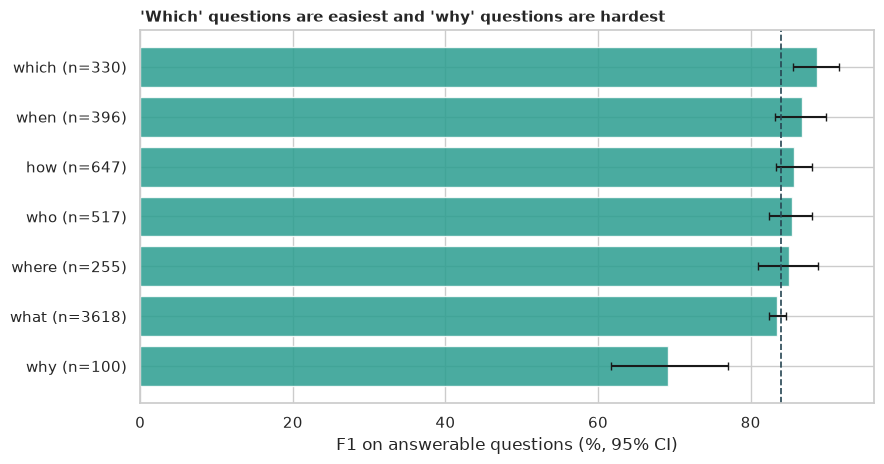

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(
    range(len(by_word)),
    by_word["F1"] * 100,
    color=TEAL,
    alpha=0.85,
    xerr=[(by_word["F1"] - by_word["low"]) * 100, (by_word["high"] - by_word["F1"]) * 100],
    capsize=3,
)
ax.set_yticks(
    range(len(by_word)),
    [f"{w} (n={n})" for w, n in zip(by_word.index, by_word["questions"], strict=True)],
)
ax.axvline(answerable["f1"].mean() * 100, color=NAVY, ls="--", lw=1.2)
ax.set_xlabel("F1 on answerable questions (%, 95% CI)")
ax.set_title(
    "'Which' questions are easiest and 'why' questions are hardest",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_question_types.png", dpi=150)
plt.show()

**How to read this:**

- **The question word matters:** F1 on answerable questions is **0.887** for "which", **0.868** for "when", **0.857** for "how", **0.854** for "who", **0.850** for "where", **0.835** for "what" and only **0.691** for "why" (CI 0.616 to 0.771, 100 questions). Kruskal-Wallis p = **5e-13**. **We reject H₀.** Questions with a name, number or date as the answer are easiest; "why" needs a clause as the answer, and exact boundaries are less clear.
- **Paragraph length does not matter here:** Spearman **-0.004** (p = 0.78); F1 by length quarter is 0.844, 0.829, 0.856 and 0.832. These paragraphs are short, so even the longest quarter fits in one window.
- **Most answerable-question failures are over-caution:** **12.6%** of the answerable questions get F1 = 0, and for **76.6%** of these the model said "no answer". The model rarely gives a wrong span; it more often refuses an answer that was there.

## 9. H4: the legacy questions, replayed

*What:* the seven hand-written questions of the legacy notebook (four in `train.json`, three in `test.json`), answered by both models **without any training on them**. Two of the seven have no answer in their paragraph. *Why:* a quick sanity check on the original task; with seven questions it shows what the models do, not how good they are.

In [10]:
legacy_rows = []
for split in ("train", "test"):
    for item in json.loads(Path(f"{split}.json").read_text()):
        for qa in item["qas"]:
            legacy_rows.append(
                {
                    "file": split,
                    "question": qa["question"],
                    "context": item["context"],
                    "gold": [a["text"] for a in qa["answers"]],
                }
            )
legacy = pd.DataFrame(legacy_rows)
legacy_v2, legacy_margin = predict_spans(
    MODEL_V2, legacy["question"].tolist(), legacy["context"].tolist()
)
legacy_v1, _ = predict_spans(MODEL_V1, legacy["question"].tolist(), legacy["context"].tolist())
legacy["RoBERTa"] = ["" if m > 0 else t for m, t in zip(legacy_margin, legacy_v2, strict=True)]
legacy["DistilBERT"] = legacy_v1
print(
    f"{len(legacy)} hand-made questions in the legacy files "
    f"({(legacy['gold'].map(len) == 0).sum()} have no answer in the paragraph); both models "
    "answer them with no training on them:"
)
for _, row in legacy.iterrows():
    truth = row["gold"][0] if row["gold"] else "(no answer)"
    print(
        f"  Q: {row['question']}\n     truth: {truth!r}\n     RoBERTa: "
        f"{row['RoBERTa'] or '(no answer)'!r}; DistilBERT: {row['DistilBERT']!r}"
    )
for name in ("RoBERTa", "DistilBERT"):
    em = np.mean([exact_match(p, g) for p, g in zip(legacy[name], legacy["gold"], strict=True)])
    f1 = np.mean([f1_score(p, g) for p, g in zip(legacy[name], legacy["gold"], strict=True)])
    print(f"{name}: exact match {em:.2f}, F1 {f1:.2f} on {len(legacy)} questions")

7 hand-made questions in the legacy files (2 have no answer in the paragraph); both models answer them with no training on them:
  Q: Who is the author of the Mistborn series?
     truth: 'Brandon Sanderson'
     RoBERTa: 'Brandon Sanderson'; DistilBERT: 'Brandon Sanderson'
  Q: When was the series published?
     truth: 'between 2006 and 2008'
     RoBERTa: 'between 2006 and 2008'; DistilBERT: 'between 2006 and 2008'
  Q: What are the three books in the series?
     truth: 'The Final Empire, The Well of Ascension, and The Hero of Ages'
     RoBERTa: 'The Final Empire,The Well of Ascension, and The Hero of Ages'; DistilBERT: 'The Final Empire,The Well of Ascension, and The Hero of Ages'
  Q: Who is the main character in the series?
     truth: '(no answer)'
     RoBERTa: '(no answer)'; DistilBERT: 'The Hero of Ages'
  Q: Where does the series take place?
     truth: 'region called the Final Empire'
     RoBERTa: 'the Final Empire on a world called Scadrial'; DistilBERT: 'Scadrial'
  Q:

**How to read this:**

- **The abstaining RoBERTa gets 4 of 7 exactly right (exact match 0.57, F1 0.79),** and DistilBERT 2 of 7 (0.29, F1 0.53).
- **The unanswerable questions show H1 in miniature:** asked "Who is the main character in the series?", where the paragraph never says, RoBERTa answers "no answer" and DistilBERT says "The Hero of Ages" (a book title); asked "What are Allomantic powers?", DistilBERT answers `Mistborns"`.
- **RoBERTa is over-cautious once:** "How many powers does a Misting possess?" (answer "one") gets "no answer", while DistilBERT gives "one of the many Allomantic powers".
- **A note on the scoring:** for the question about the three books, both models return the right list, but the legacy paragraph has a typo ("Empire,The" without a space), so exact match counts it as wrong while F1 gives it partial credit. Seven questions are far too few to tell the models apart.

## 10. 🎯 Takeaways

1. **A benchmark that is half traps rewards saying "I don't know":** a model forced to answer scores **0.421** exact match on SQuAD 2.0 (zero on the unanswerable half); the same model allowed to refuse scores **0.799**.
2. **Refusing has a price:** exact match on the answerable questions falls from 0.843 to 0.780 (371 answers lost, none gained), a trade that is worth it by about 38 points overall.
3. **The default threshold is already close to the best:** tuning moves it from 0 to -1.50 for +0.44 points of F1 (overlapping intervals).
4. **Questions that need a clause are harder than ones that need a name:** F1 is 0.887 for "which" and 0.691 for "why".
5. **Most mistakes on answerable questions are refusals:** the model said "no answer" in 76.6% of the answerable questions it got completely wrong.
6. **Seven questions cannot evaluate anything;** the benchmark has 11,873.

## 11. ⚠️ Limitations

- **Wikipedia paragraphs and crowd-written questions.** Real users ask different, messier questions, over longer documents, and many questions need more than one paragraph.
- **The unanswerable questions in SQuAD 2.0 are adversarial:** they were written to look answerable, so refusal rates here are not those of real use.
- **DistilBERT is a different, smaller model,** so the comparison with RoBERTa mixes architecture and training data; only the forced and abstaining RoBERTa systems isolate the effect of abstaining.
- **Exact match and F1 are word-overlap metrics:** they reward matching the references' wording and give no credit for a correct answer in other words.
- **The threshold was tuned on half of the data once;** a different split could pick a different value (the curve is flat).
- **The question-word groups overlap in other ways** (difficulty, article topic) and "why" has only 100 questions.
- **The legacy questions are seven and written by one person,** so H4 is a demonstration.
- **Models were used as published:** no fine-tuning, no check across topics, dialects or demographic groups.